In [19]:
# Step 1: Import Libraries and Load the Dataset
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_name = 'netflix_titles.csv'

if not os.path.exists(file_name):
    print(f"'{file_name}' not found. Generating a local sample dataset for testing...")

    sample_data = {
        'show_id': [f's{i}' for i in range(1, 101)],
        'type': ['Movie' if i % 3 != 0 else 'TV Show' for i in range(1, 101)],
        'title': [f'Sample Title {i}' for i in range(1, 101)],
        'director': ['Rajkumar Hirani' if i % 10 == 0 else ('Christopher Nolan' if i % 10 == 3 else np.nan) for i in range(1, 101)],
        'cast': ['Actor A, Actor B' if i % 2 == 0 else np.nan for i in range(1, 101)],
        'country': ['United States' if i % 2 == 0 else ('India' if i % 3 == 0 else 'United Kingdom, United States') for i in range(1, 101)],
        'date_added': [f'August {1 + (i % 28)}, 2019' if i % 2 == 0 else f'January {1 + (i % 28)}, 2021' for i in range(1, 101)],
        'release_year': [2015 + (i % 7) for i in range(1, 101)],
        'rating': ['PG-13' if i % 4 == 0 else 'TV-MA' for i in range(1, 101)],
        'duration': ['120 min' if i % 3 != 0 else '2 Seasons' for i in range(1, 101)],
        'listed_in': ['Dramas, International Movies' if i % 3 != 0 else 'Docuseries, International TV Shows' for i in range(1, 101)],
        'description': ['A great sample description for testing Netflix EDA.' for i in range(1, 101)]
    }
    df_temp = pd.DataFrame(sample_data)
    df_temp.to_csv(file_name, index=False)
    print(f"Generated fallback file: '{file_name}'.")

df = pd.read_csv(file_name)
print(f"Data loaded successfully! Shape: {df.shape[0]} rows, {df.shape[1]} columns.")

Data loaded successfully! Shape: 100 rows, 12 columns.


In [20]:
# Step 2: Inspecting the Dataset
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")

print("First 5 rows:")
display(df.head())

print("\nDataset Columns and Types:")
df.info()

Dataset Shape: 100 rows and 12 columns

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Sample Title 1,NaN,NaN,"United Kingdom, United States","January 2, 2021",2016,TV-MA,120 min,"Dramas, International Movies",A great sample description for testing Netflix...
1,s2,Movie,Sample Title 2,NaN,"Actor A, Actor B",United States,"August 3, 2019",2017,TV-MA,120 min,"Dramas, International Movies",A great sample description for testing Netflix...
2,s3,TV Show,Sample Title 3,Christopher Nolan,NaN,India,"January 4, 2021",2018,TV-MA,2 Seasons,"Docuseries, International TV Shows",A great sample description for testing Netflix...
3,s4,Movie,Sample Title 4,NaN,"Actor A, Actor B",United States,"August 5, 2019",2019,PG-13,120 min,"Dramas, International Movies",A great sample description for testing Netflix...
4,s5,Movie,Sample Title 5,NaN,NaN,"United Kingdom, United States","January 6, 2021",2020,TV-MA,120 min,"Dramas, International Movies",A great sample description for testing Netflix...



Dataset Columns and Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       100 non-null    object
 1   type          100 non-null    object
 2   title         100 non-null    object
 3   director      20 non-null     object
 4   cast          50 non-null     object
 5   country       100 non-null    object
 6   date_added    100 non-null    object
 7   release_year  100 non-null    int64 
 8   rating        100 non-null    object
 9   duration      100 non-null    object
 10  listed_in     100 non-null    object
 11  description   100 non-null    object
dtypes: int64(1), object(11)
memory usage: 9.5+ KB


In [21]:
# Step 3: Handling Missing Values and Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

missing_count = df.isnull().sum()
print("\nMissing values per column:")
print(missing_count)

df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

if df['rating'].isnull().any():
    df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

print("\nMissing values after cleanup:")
print(df.isnull().sum())

Number of duplicate rows: 0

Missing values per column:
show_id          0
type             0
title            0
director        80
cast            50
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Missing values after cleanup:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


/tmp/ipykernel_3946/1313136895.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set2')


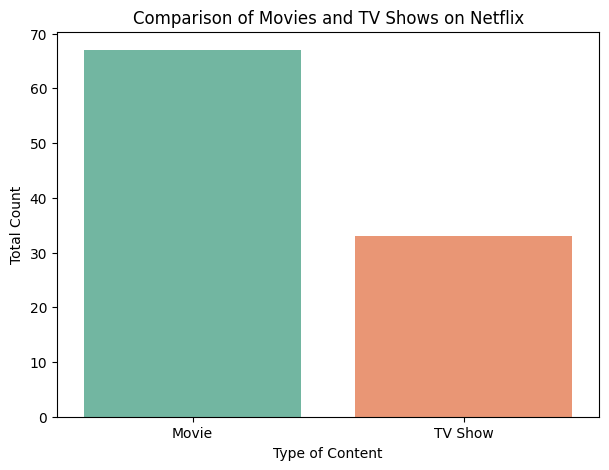

Movies: 67 (67.00%)
TV Shows: 33 (33.00%)


In [22]:
# Step 4: Comparing Movies vs. TV Shows on Netflix
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='type', palette='Set2')
plt.title('Comparison of Movies and TV Shows on Netflix')
plt.xlabel('Type of Content')
plt.ylabel('Total Count')
plt.show()

type_counts = df['type'].value_counts()
for category, count in type_counts.items():
    percentage = (count / len(df)) * 100
    print(f"{category}s: {count} ({percentage:.2f}%)")

/tmp/ipykernel_3946/1197453817.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


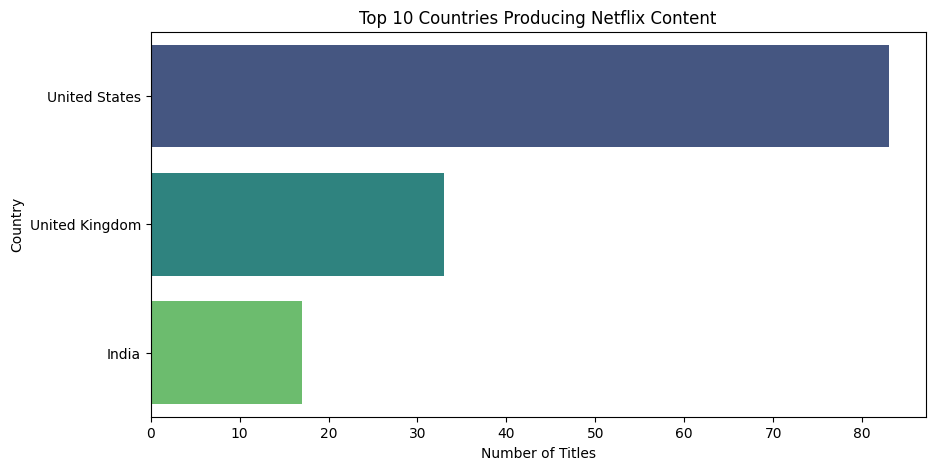

In [23]:
# Step 5: Finding the Top 10 Countries with the Most Content
split_countries = df['country'].str.split(', ').explode()

cleaned_countries = split_countries[split_countries != 'Unknown']
top_countries = cleaned_countries.value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

/tmp/ipykernel_3946/2261164279.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette='magma')


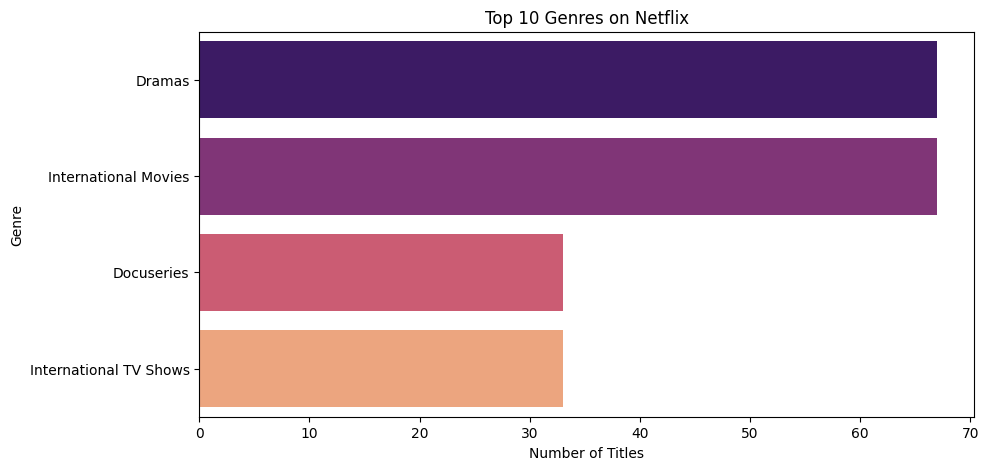

In [24]:
# Step 6: Most Common Genres on Netflix
split_genres = df['listed_in'].str.split(', ').explode()
top_genres = split_genres.value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette='magma')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

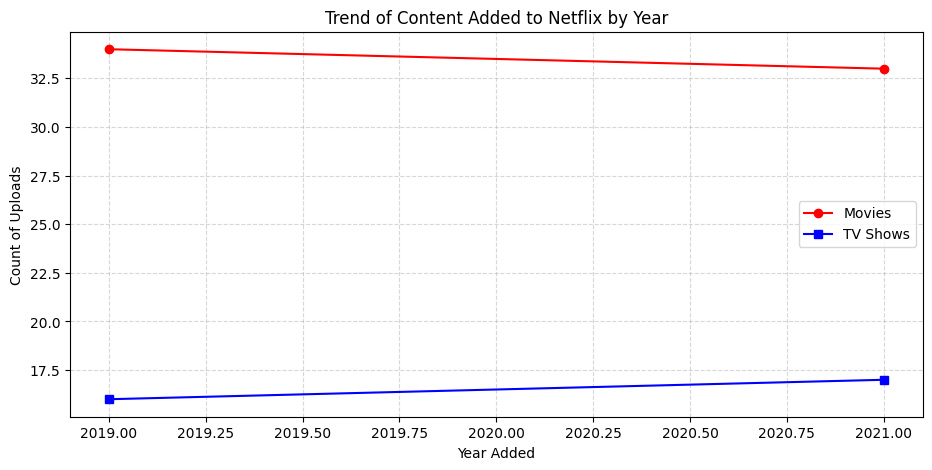

In [25]:
# Step 7: Content Added to Netflix Over Time
df['date_added_clean'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added_clean'].dt.year

yearly_content = df.groupby(['year_added', 'type']).size().reset_index(name='count')
pivoted_data = yearly_content.pivot(index='year_added', columns='type', values='count').fillna(0)

plt.figure(figsize=(11, 5))
plt.plot(pivoted_data.index, pivoted_data['Movie'], marker='o', color='red', label='Movies')
plt.plot(pivoted_data.index, pivoted_data['TV Show'], marker='s', color='blue', label='TV Shows')
plt.title('Trend of Content Added to Netflix by Year')
plt.xlabel('Year Added')
plt.ylabel('Count of Uploads')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

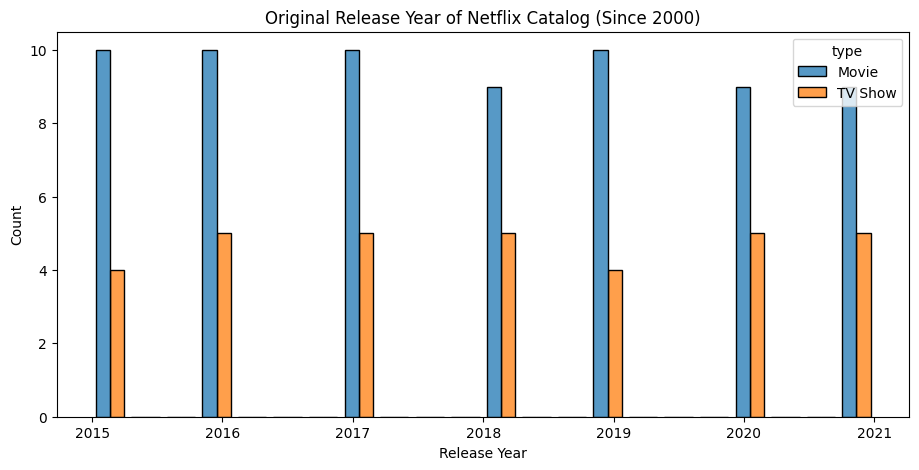

In [26]:
# Step 8: Comparing Movies and TV Shows by Original Release Year
recent_releases = df[df['release_year'] >= 2000]

plt.figure(figsize=(11, 5))
sns.histplot(data=recent_releases, x='release_year', hue='type', multiple='dodge', bins=22, shrink=0.8)
plt.title('Original Release Year of Netflix Catalog (Since 2000)')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.show()